# Bank Customer Churn Analysis

## Objective

Analyze bank customer churn data to identify the key factors associated with customers leaving the bank.

## Key Objectives

- Analyze customer demographics and banking attributes.
- Examine age, balance, activity, tenure, and credit score.
- Compare characteristics of churned and retained customers.
- Perform correlation analysis between numerical attributes and churn.
- Visualize churn patterns using heatmaps, bar charts, and distribution plots.
- Summarize major findings and provide business recommendations.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
df = pd.read_csv("../data/churn.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [6]:
print("Dataset Information")
print("=" * 50)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Information
Rows: 10000
Columns: 14

Column Names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

Data Types:
RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [8]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
CustomerId,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
NumOfProducts,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0


In [9]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

,Missing Values,Missing Percentage
RowNumber,0,0.0
CustomerId,0,0.0
Surname,0,0.0
CreditScore,0,0.0
Geography,0,0.0
Gender,0,0.0
Age,0,0.0
Tenure,0,0.0
Balance,0,0.0
NumOfProducts,0,0.0


In [10]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [11]:
categorical_columns = [
    "Geography",
    "Gender",
    "HasCrCard",
    "IsActiveMember",
    "Exited"
]

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts())


Geography
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender
Gender
Male      5457
Female    4543
Name: count, dtype: int64

HasCrCard
HasCrCard
1    7055
0    2945
Name: count, dtype: int64

IsActiveMember
IsActiveMember
1    5151
0    4849
Name: count, dtype: int64

Exited
Exited
0    7963
1    2037
Name: count, dtype: int64


In [12]:
df_clean = df.copy()

df_clean = df_clean.drop(
    columns=["RowNumber", "CustomerId", "Surname"]
)

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (10000, 14)
Cleaned shape: (10000, 11)


In [13]:
churn_counts = df_clean["Exited"].value_counts()

print("Customer Churn Distribution")
print("=" * 40)
print(churn_counts)

Customer Churn Distribution
Exited
0    7963
1    2037
Name: count, dtype: int64


In [14]:
churn_percentage = (
    df_clean["Exited"]
    .value_counts(normalize=True)
    .mul(100)
)

print("Churn Percentage:")
print(churn_percentage)

Churn Percentage:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


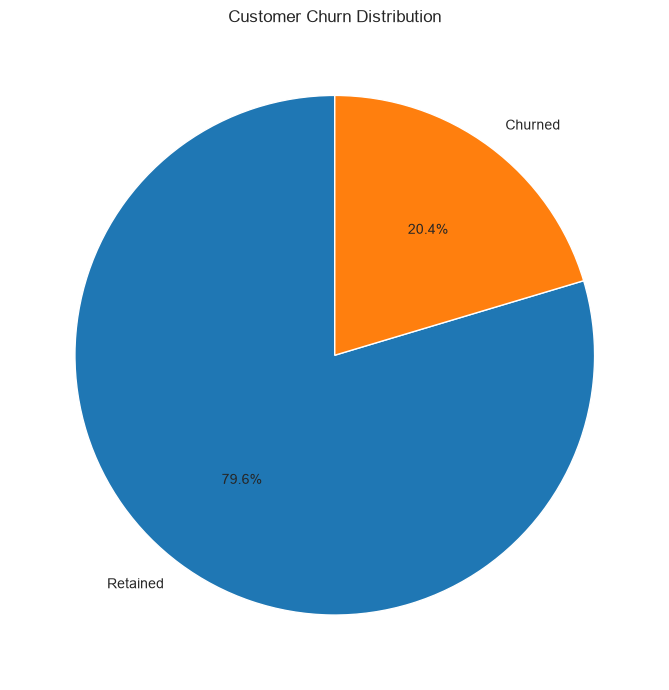

In [15]:
plt.figure(figsize=(7, 7))

plt.pie(
    churn_counts.values,
    labels=["Retained", "Churned"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Churn Distribution")

plt.tight_layout()

plt.savefig(
    "../visuals/churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
print("Customer Statistics")
print("=" * 50)

print(f"Average Age: {df_clean['Age'].mean():.2f}")
print(f"Average Credit Score: {df_clean['CreditScore'].mean():.2f}")
print(f"Average Tenure: {df_clean['Tenure'].mean():.2f} years")
print(f"Average Balance: ${df_clean['Balance'].mean():,.2f}")
print(f"Average Estimated Salary: ${df_clean['EstimatedSalary'].mean():,.2f}")

Customer Statistics
Average Age: 38.92
Average Credit Score: 650.53
Average Tenure: 5.01 years
Average Balance: $76,485.89
Average Estimated Salary: $100,090.24


In [17]:
churn_comparison = df_clean.groupby("Exited")[
    ["Age", "CreditScore", "Tenure", "Balance",
     "NumOfProducts", "EstimatedSalary"]
].mean()

churn_comparison.index = ["Retained", "Churned"]

churn_comparison

,Age,CreditScore,Tenure,Balance,NumOfProducts,EstimatedSalary
Retained,37.408389,651.853196,5.033279,72745.296779,1.544267,99738.391772
Churned,44.837997,645.351497,4.932744,91108.539337,1.475209,101465.677531


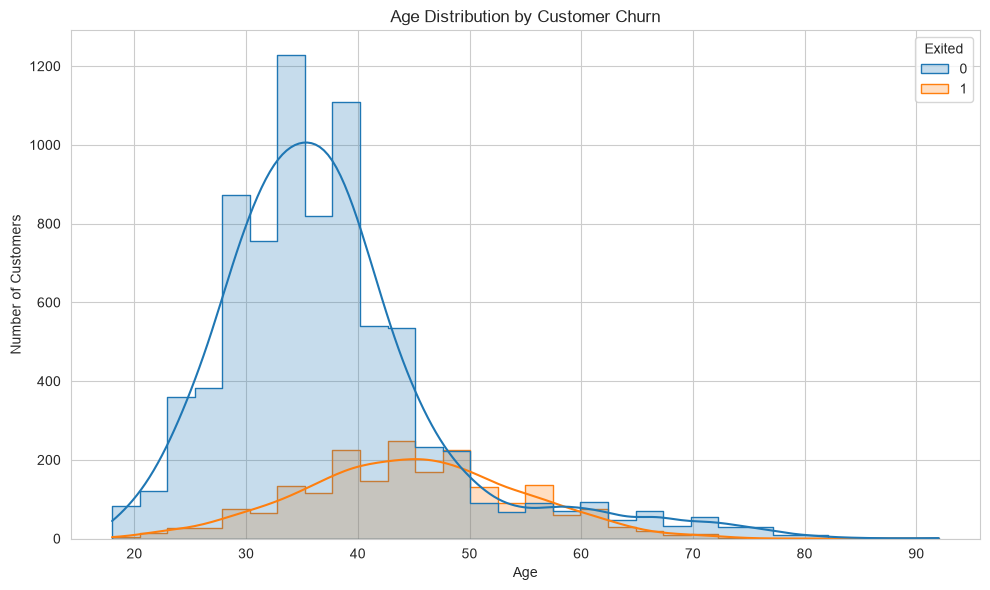

In [18]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="Age",
    hue="Exited",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Age Distribution by Customer Churn")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../visuals/age_distribution_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

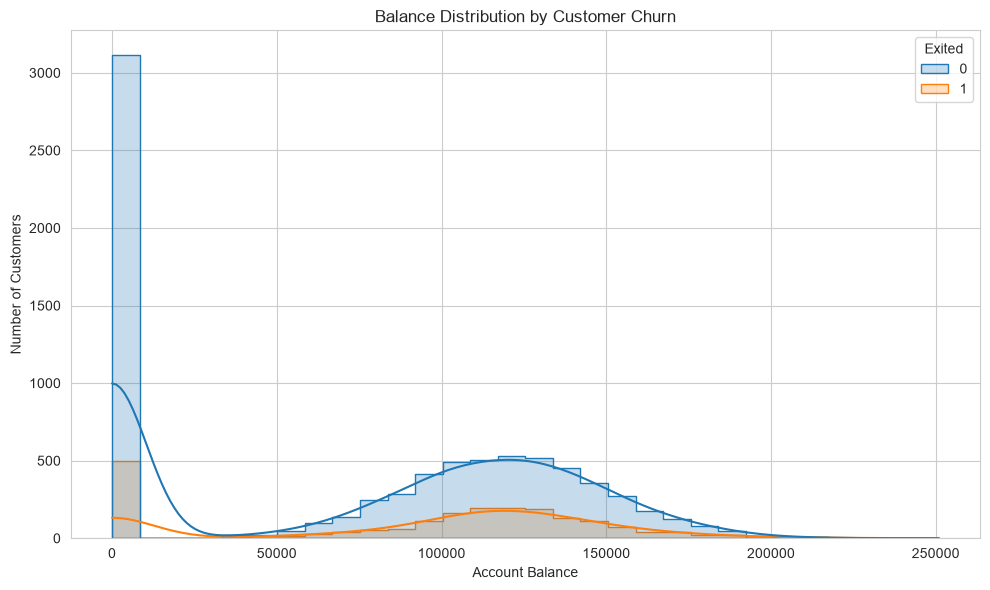

In [19]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="Balance",
    hue="Exited",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Balance Distribution by Customer Churn")
plt.xlabel("Account Balance")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../visuals/balance_distribution_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

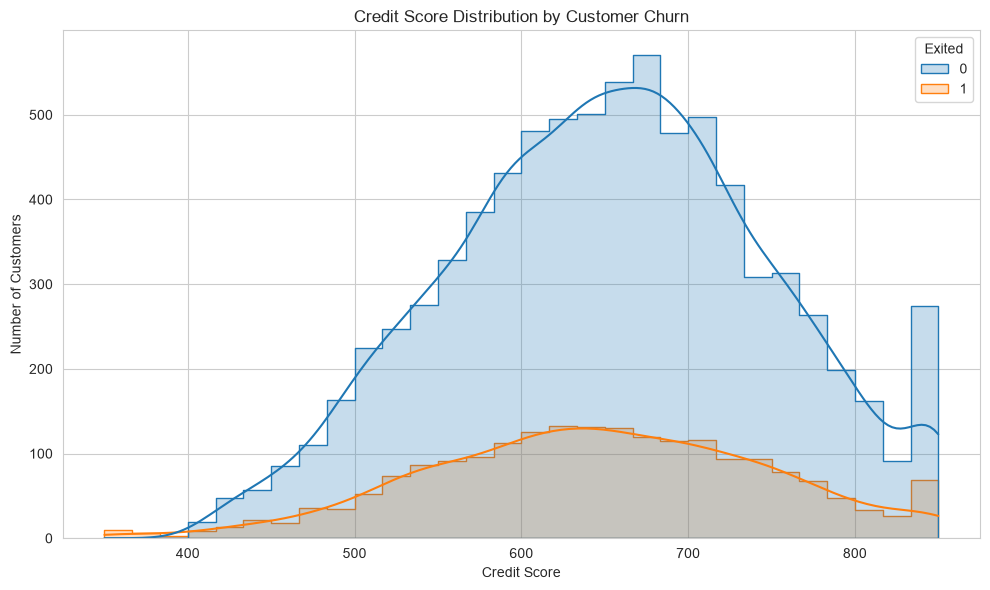

In [20]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="CreditScore",
    hue="Exited",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Credit Score Distribution by Customer Churn")
plt.xlabel("Credit Score")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../visuals/credit_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
tenure_churn = pd.crosstab(
    df_clean["Tenure"],
    df_clean["Exited"]
)

tenure_churn.columns = ["Retained", "Churned"]

tenure_churn

,Retained,Churned
Tenure,,
0,318,95
1,803,232
2,847,201
3,796,213
4,786,203
5,803,209
6,771,196
7,851,177
8,828,197


<Figure size 1000x600 with 0 Axes>

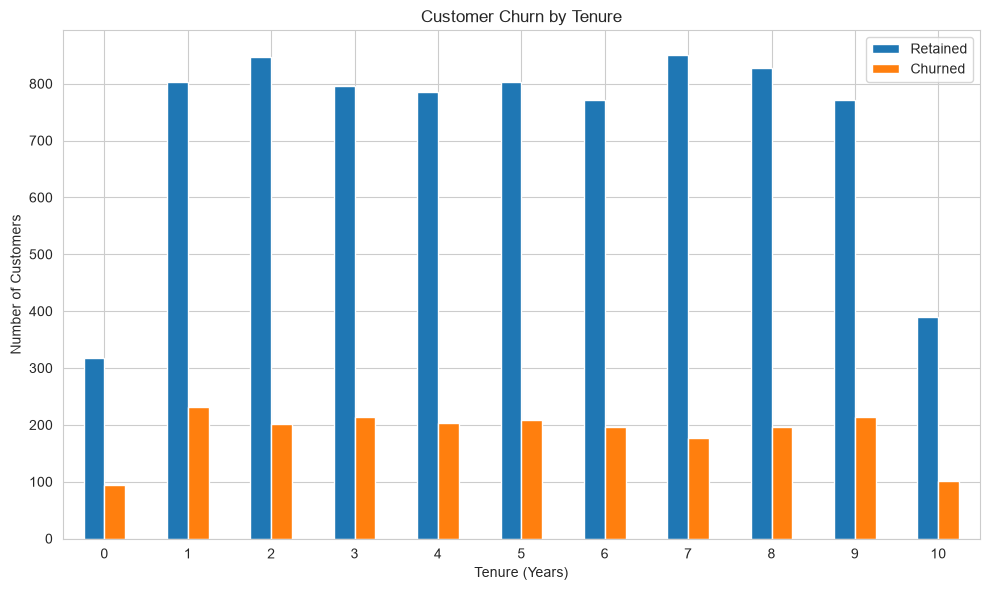

In [22]:
plt.figure(figsize=(10, 6))

tenure_churn.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Customer Churn by Tenure")
plt.xlabel("Tenure (Years)")
plt.ylabel("Number of Customers")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../visuals/churn_by_tenure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
activity_churn = pd.crosstab(
    df_clean["IsActiveMember"],
    df_clean["Exited"]
)

activity_churn.columns = ["Retained", "Churned"]

activity_churn

,Retained,Churned
IsActiveMember,,
0,3547,1302
1,4416,735


In [24]:
activity_churn_rate = (
    df_clean.groupby("IsActiveMember")["Exited"]
    .mean()
    .mul(100)
)

print("Churn Rate by Membership Activity")
print(activity_churn_rate)

Churn Rate by Membership Activity
IsActiveMember
0    26.850897
1    14.269074
Name: Exited, dtype: float64


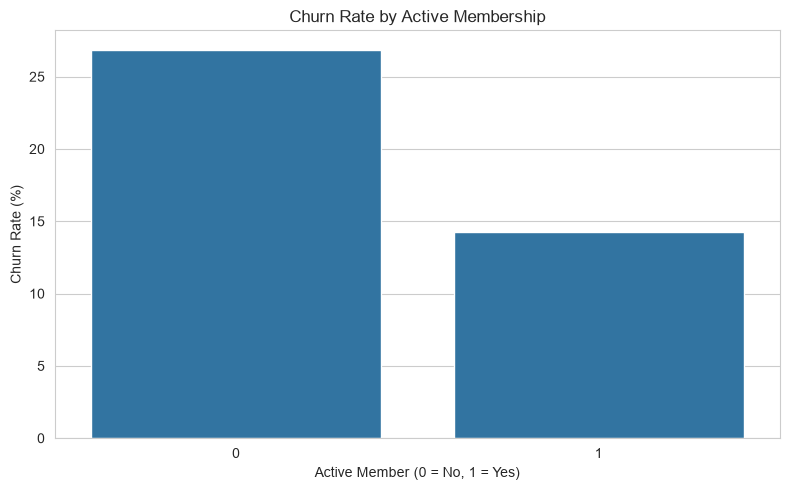

In [25]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=activity_churn_rate.index,
    y=activity_churn_rate.values
)

plt.title("Churn Rate by Active Membership")
plt.xlabel("Active Member (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()

plt.savefig(
    "../visuals/churn_rate_active_members.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
geography_churn = (
    df_clean.groupby("Geography")["Exited"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("Churn Rate by Geography")
print(geography_churn)

Churn Rate by Geography
Geography
Germany    32.443204
Spain      16.673395
France     16.154767
Name: Exited, dtype: float64


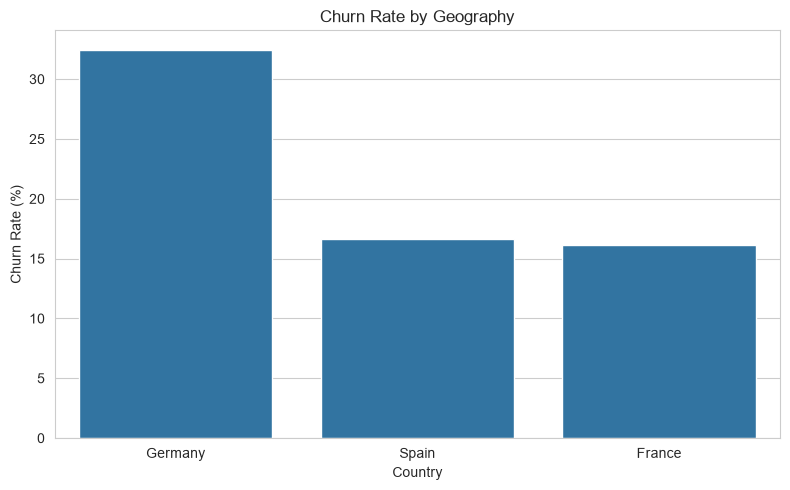

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=geography_churn.index,
    y=geography_churn.values
)

plt.title("Churn Rate by Geography")
plt.xlabel("Country")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()

plt.savefig(
    "../visuals/churn_rate_geography.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
gender_churn = (
    df_clean.groupby("Gender")["Exited"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("Churn Rate by Gender")
print(gender_churn)

Churn Rate by Gender
Gender
Female    25.071539
Male      16.455928
Name: Exited, dtype: float64


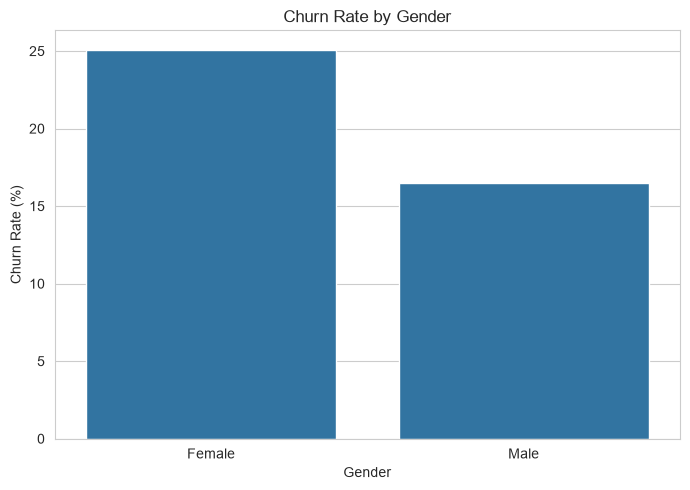

In [29]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_churn.index,
    y=gender_churn.values
)

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()

plt.savefig(
    "../visuals/churn_rate_gender.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
product_churn = (
    df_clean.groupby("NumOfProducts")["Exited"]
    .mean()
    .mul(100)
)

print("Churn Rate by Number of Products")
print(product_churn)

Churn Rate by Number of Products
NumOfProducts
1     27.714398
2      7.581699
3     82.706767
4    100.000000
Name: Exited, dtype: float64


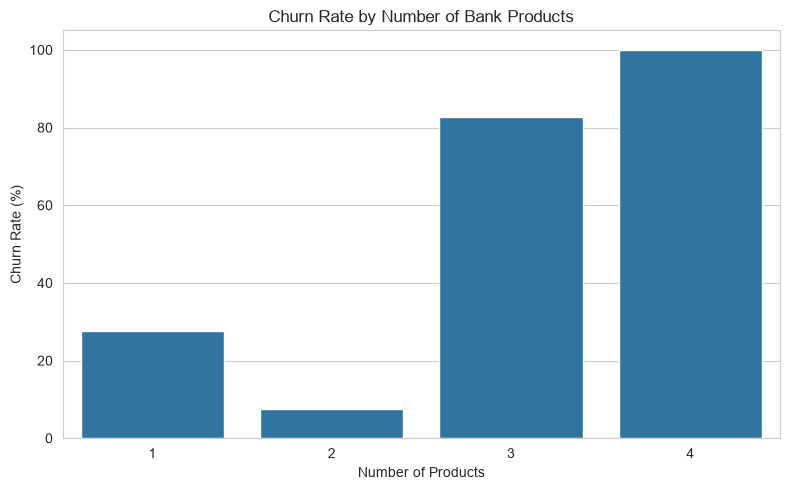

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=product_churn.index,
    y=product_churn.values
)

plt.title("Churn Rate by Number of Bank Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()

plt.savefig(
    "../visuals/churn_rate_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
credit_card_churn = (
    df_clean.groupby("HasCrCard")["Exited"]
    .mean()
    .mul(100)
)

print("Churn Rate by Credit Card Ownership")
print(credit_card_churn)

Churn Rate by Credit Card Ownership
HasCrCard
0    20.814941
1    20.184266
Name: Exited, dtype: float64


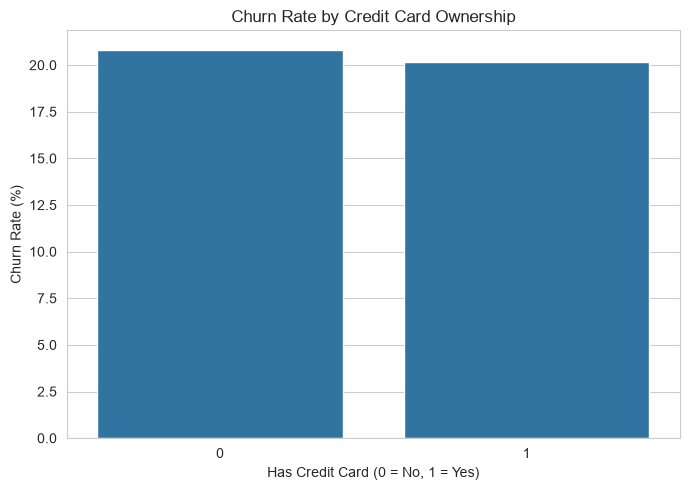

In [33]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=credit_card_churn.index,
    y=credit_card_churn.values
)

plt.title("Churn Rate by Credit Card Ownership")
plt.xlabel("Has Credit Card (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()

plt.savefig(
    "../visuals/churn_rate_credit_card.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
numeric_columns = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited"
]

correlation_matrix = df_clean[numeric_columns].corr()

correlation_matrix

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
CreditScore,1.000000,-0.003965,0.000842,0.006268,0.012238,-0.005458,0.025651,-0.001384,-0.027094
Age,-0.003965,1.000000,-0.009997,0.028308,-0.030680,-0.011721,0.085472,-0.007201,0.285323
Tenure,0.000842,-0.009997,1.000000,-0.012254,0.013444,0.022583,-0.028362,0.007784,-0.014001
Balance,0.006268,0.028308,-0.012254,1.000000,-0.304180,-0.014858,-0.010084,0.012797,0.118533
NumOfProducts,0.012238,-0.030680,0.013444,-0.304180,1.000000,0.003183,0.009612,0.014204,-0.047820
HasCrCard,-0.005458,-0.011721,0.022583,-0.014858,0.003183,1.000000,-0.011866,-0.009933,-0.007138
IsActiveMember,0.025651,0.085472,-0.028362,-0.010084,0.009612,-0.011866,1.000000,-0.011421,-0.156128
EstimatedSalary,-0.001384,-0.007201,0.007784,0.012797,0.014204,-0.009933,-0.011421,1.000000,0.012097
Exited,-0.027094,0.285323,-0.014001,0.118533,-0.047820,-0.007138,-0.156128,0.012097,1.000000


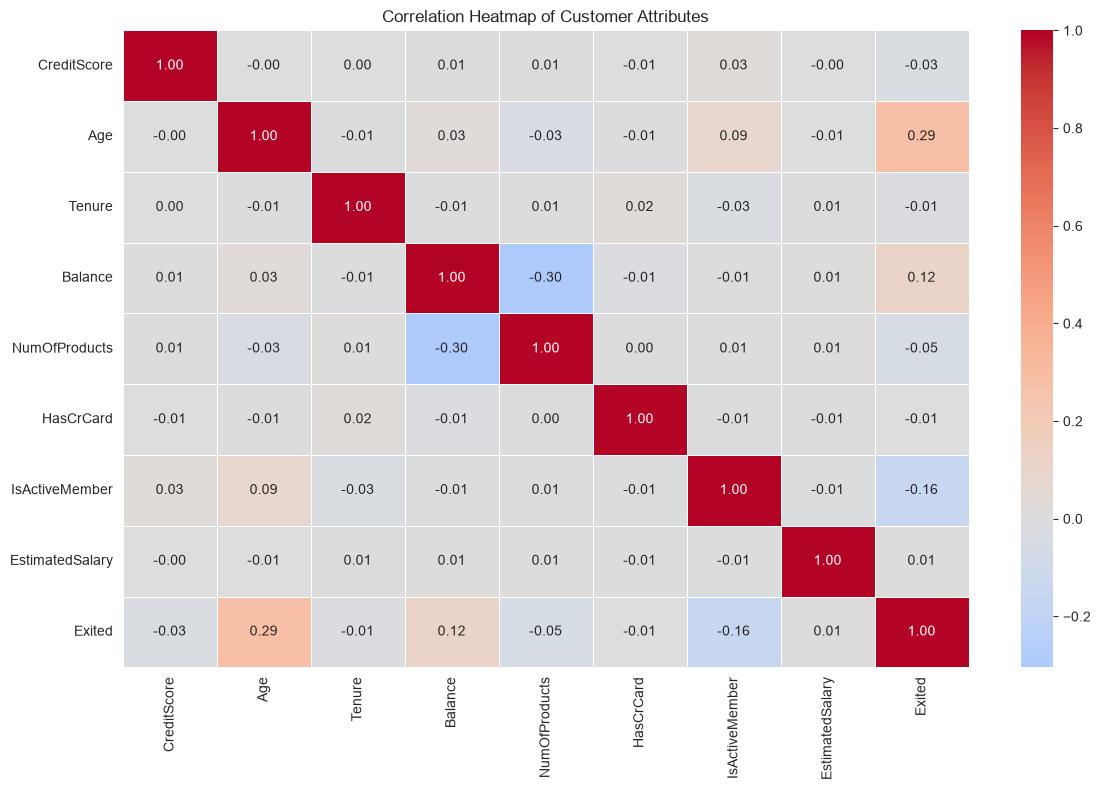

In [35]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Customer Attributes")

plt.tight_layout()

plt.savefig(
    "../visuals/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
churn_correlations = (
    correlation_matrix["Exited"]
    .drop("Exited")
    .sort_values(ascending=False)
)

print("Correlation with Customer Churn")
print("=" * 40)
print(churn_correlations)

Correlation with Customer Churn
Age                0.285323
Balance            0.118533
EstimatedSalary    0.012097
HasCrCard         -0.007138
Tenure            -0.014001
CreditScore       -0.027094
NumOfProducts     -0.047820
IsActiveMember    -0.156128
Name: Exited, dtype: float64


In [37]:
df_clean["AgeGroup"] = pd.cut(
    df_clean["Age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "66+"
    ]
)

In [38]:
age_group_churn = (
    df_clean.groupby("AgeGroup", observed=False)["Exited"]
    .mean()
    .mul(100)
)

print("Churn Rate by Age Group")
print(age_group_churn)

Churn Rate by Age Group
AgeGroup
18-25     7.528642
26-35     8.498024
36-45    19.619914
46-55    50.572082
56-65    48.320896
66+      13.257576
Name: Exited, dtype: float64


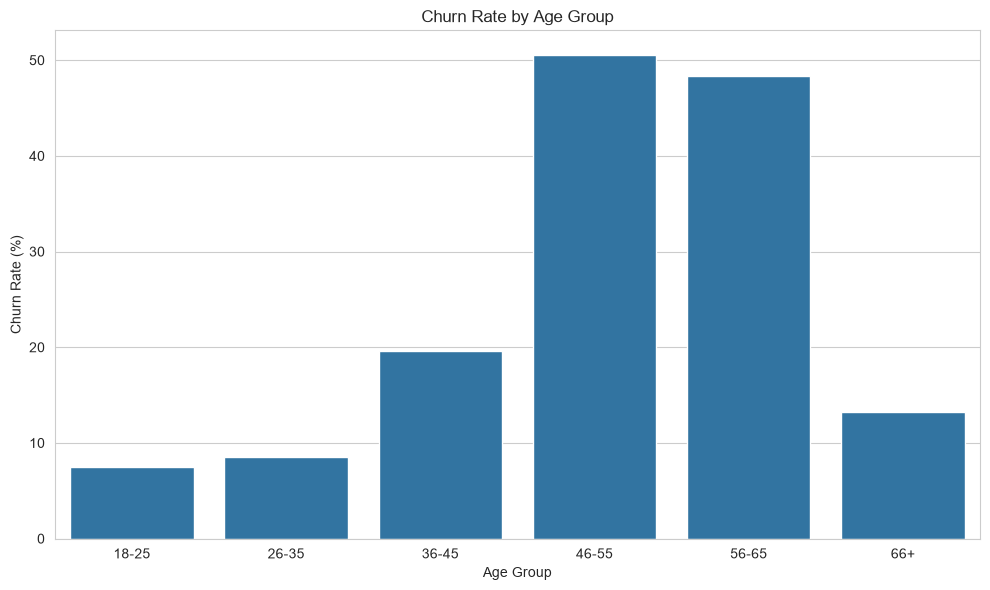

In [39]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=age_group_churn.index,
    y=age_group_churn.values
)

plt.title("Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()

plt.savefig(
    "../visuals/churn_rate_age_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

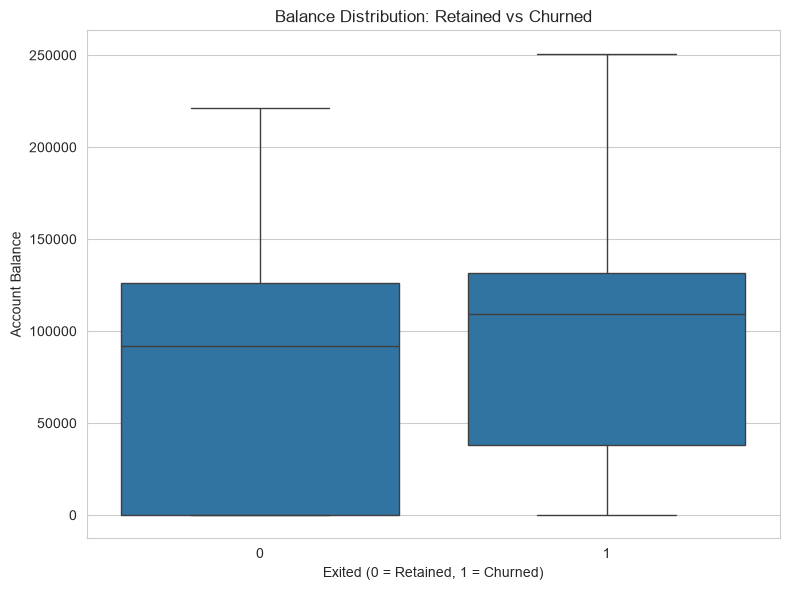

In [40]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df_clean,
    x="Exited",
    y="Balance"
)

plt.title("Balance Distribution: Retained vs Churned")
plt.xlabel("Exited (0 = Retained, 1 = Churned)")
plt.ylabel("Account Balance")

plt.tight_layout()

plt.savefig(
    "../visuals/balance_boxplot_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

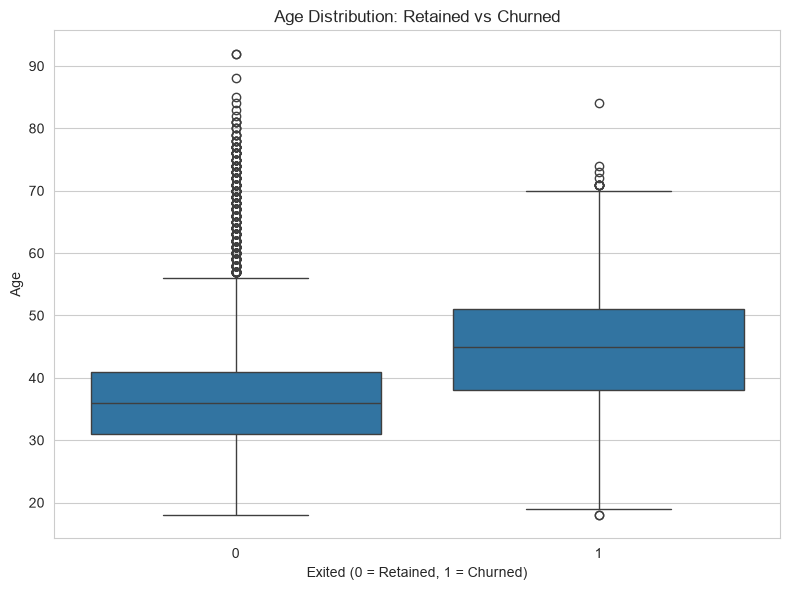

In [41]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df_clean,
    x="Exited",
    y="Age"
)

plt.title("Age Distribution: Retained vs Churned")
plt.xlabel("Exited (0 = Retained, 1 = Churned)")
plt.ylabel("Age")

plt.tight_layout()

plt.savefig(
    "../visuals/age_boxplot_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
print("MAJOR CHURN PATTERNS")
print("=" * 60)

print(
    f"Overall churn rate: "
    f"{df_clean['Exited'].mean() * 100:.2f}%"
)

print(
    f"\nAverage age - retained: "
    f"{df_clean[df_clean['Exited'] == 0]['Age'].mean():.2f}"
)

print(
    f"Average age - churned: "
    f"{df_clean[df_clean['Exited'] == 1]['Age'].mean():.2f}"
)

print(
    f"\nAverage balance - retained: "
    f"${df_clean[df_clean['Exited'] == 0]['Balance'].mean():,.2f}"
)

print(
    f"Average balance - churned: "
    f"${df_clean[df_clean['Exited'] == 1]['Balance'].mean():,.2f}"
)

print(
    f"\nAverage credit score - retained: "
    f"{df_clean[df_clean['Exited'] == 0]['CreditScore'].mean():.2f}"
)

print(
    f"Average credit score - churned: "
    f"{df_clean[df_clean['Exited'] == 1]['CreditScore'].mean():.2f}"
)

print(
    f"\nAverage tenure - retained: "
    f"{df_clean[df_clean['Exited'] == 0]['Tenure'].mean():.2f}"
)

print(
    f"Average tenure - churned: "
    f"{df_clean[df_clean['Exited'] == 1]['Tenure'].mean():.2f}"
)

MAJOR CHURN PATTERNS
Overall churn rate: 20.37%

Average age - retained: 37.41
Average age - churned: 44.84

Average balance - retained: $72,745.30
Average balance - churned: $91,108.54

Average credit score - retained: 651.85
Average credit score - churned: 645.35

Average tenure - retained: 5.03
Average tenure - churned: 4.93


## Key Business Insights

The analysis indicates several important patterns in customer churn:

1. **Customer Age:** Churn behavior differs across age groups, allowing the bank to identify age segments with relatively higher churn.

2. **Account Balance:** The balance distribution between retained and churned customers provides insight into whether account value is associated with customer retention.

3. **Credit Score:** Credit score shows a measurable relationship with churn and can be considered when identifying customer segments requiring attention.

4. **Customer Activity:** Active membership is an important behavioral indicator. Comparing churn rates between active and inactive members helps identify customers who may require stronger engagement.

5. **Tenure:** Churn rates vary across customer tenure levels, indicating that customer retention strategies may need to differ across relationship stages.

6. **Number of Products:** Customers with different numbers of banking products exhibit different churn patterns, making product engagement an important factor to investigate.

7. **Geography:** Churn rates differ across geographical regions, suggesting that customer retention strategies may need to account for regional differences.

8. **Correlation:** Correlation analysis helps identify variables associated with churn. However, correlation does not establish causation.

## Recommendations

- Develop targeted retention campaigns for customer segments with high observed churn rates.
- Increase engagement with inactive members through personalized banking offers and communication.
- Monitor older or otherwise high-risk customer segments identified through the EDA.
- Encourage appropriate product adoption where customers have low engagement with banking products.
- Investigate geographical differences in churn and develop region-specific retention strategies.
- Use customer balance, credit score, age, tenure, and activity together rather than relying on a single attribute.
- Monitor churn-related indicators regularly to identify customers who may require proactive engagement.

## Conclusion

The Bank Customer Churn Analysis provides a detailed view of the characteristics associated with customer attrition. Exploratory analysis of age, balance, credit score, tenure, activity, product usage, and geography reveals differences between retained and churned customers. Correlation analysis further highlights relationships between numerical customer attributes and churn.

These findings can help a bank design more targeted customer retention strategies, improve engagement, and identify customer segments that warrant further investigation.